In [2]:
import pandas as pd
import numpy as np 

In [3]:
df = pd.read_csv("titanic.csv",usecols=['Cabin', 'Ticket', 'Survived'])
df.head()

,Survived,Ticket,Cabin
0,0,A/5 21171,NaN
1,1,PC 17599,C85
2,1,STON/O2. 3101282,NaN
3,1,113803,C123
4,0,373450,NaN


In [4]:
df['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'B28', 'C83', 'F33',
       'F G73', 'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101',
       'F E69', 'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54',
       'B57 B59 B63 B66', 'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40',
       'T', 'C128', 'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44',
       'A34', 'C104', 'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14',
       'B37', 'C30', 'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38',
       'B39', 'B22', 'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68',
       'B41', 'A20', 'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48',
       'E58', 'C126', 'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63',
       'C62 C64',

In [5]:
df['Ticket'].unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '113572', '36973', '347088', 'PC 17605', '2661',
       'C.A. 29395', 'S.P. 3464', '3101281', '315151', 'C.A. 33111',
       'S.O.C. 14879', '2680', '1601', '348123', '349208', '374746',
       '248738', '364516', '345767', '345779', '330932', '113059',
       'SO/C 14885', '31012

In [6]:
# df['Cabin_num'] = df['Cabin'].str.extract('(\d+)') # captures numerical part 
# df['Cabin_cat'] = df['Cabin'].str[0]  # capture the first letter 

# Extract numeric part of Cabin
df['Cabin_num'] = df['Cabin'].str.extract(r'(\d+)')

# Extract first letter (cabin category)
df['Cabin_cat'] = df['Cabin'].str[0]

<Axes: xlabel='Cabin_cat'>

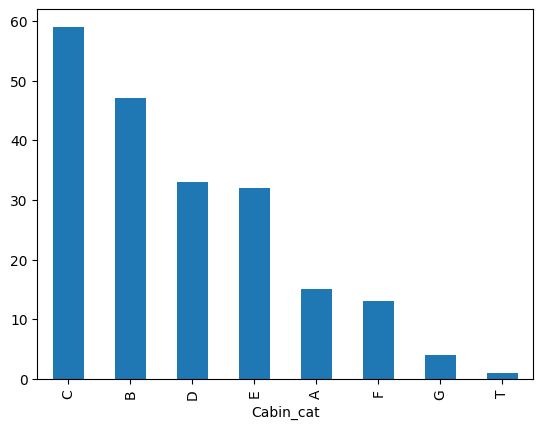

In [7]:
df['Cabin_cat'].value_counts().plot(kind='bar')

In [8]:
# extract the last bit of ticket as number 

df['Ticket_num'] = df['Ticket'].apply(lambda s: s.split()[-1])
df['Ticket_num'] = pd.to_numeric(df['Ticket_num'],
                                 errors='coerce',
                                 downcast='integer')

df['Ticket_cat'] = df['Ticket'].apply(lambda s: s.split()[0])
df['Ticket_cat'] = np.where(df['Ticket_cat'].str.isdigit(), np.nan,
                             df['Cabin_cat'])

In [9]:
df.head(10)

,Survived,Ticket,Cabin,Cabin_num,Cabin_cat,Ticket_num,Ticket_cat
0,0,A/5 21171,NaN,NaN,NaN,21171.0,NaN
1,1,PC 17599,C85,85,C,17599.0,C
2,1,STON/O2. 3101282,NaN,NaN,NaN,3101282.0,NaN
3,1,113803,C123,123,C,113803.0,NaN
4,0,373450,NaN,NaN,NaN,373450.0,NaN
5,0,330877,NaN,NaN,NaN,330877.0,NaN
6,0,17463,E46,46,E,17463.0,NaN
7,0,349909,NaN,NaN,NaN,349909.0,NaN
8,1,347742,NaN,NaN,NaN,347742.0,NaN
9,1,237736,NaN,NaN,NaN,237736.0,NaN


# DATA AND TIME VARIABLE 

In [10]:
import numpy as np
import pandas as pd
date = pd.read_csv('orders.csv')
time = pd.read_csv('messages.csv')
date.head()

,date,product_id,city_id,orders
0,2019-12-10,5628,25,3
1,2018-08-15,3646,14,157
2,2018-10-23,1859,25,1
3,2019-08-17,7292,25,1
4,2019-01-06,4344,25,3


In [11]:
time.head()

,date,msg
0,2013-12-15 00:50:00,ищу на сегодня мужика 37
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше


In [12]:
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        1000 non-null   object
 1   product_id  1000 non-null   int64 
 2   city_id     1000 non-null   int64 
 3   orders      1000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 31.4+ KB


In [13]:
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    1000 non-null   object
 1   msg     1000 non-null   object
dtypes: object(2)
memory usage: 15.8+ KB


# Working with dates

In [14]:
# converting to datetime datatype

date['date'] = pd.to_datetime(date['date'])

In [15]:
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1000 non-null   datetime64[ns]
 1   product_id  1000 non-null   int64         
 2   city_id     1000 non-null   int64         
 3   orders      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 31.4 KB


# Extract year 


In [16]:
date['date_year'] = date['date'].dt.year

date.head()

,date,product_id,city_id,orders,date_year
0,2019-12-10,5628,25,3,2019
1,2018-08-15,3646,14,157,2018
2,2018-10-23,1859,25,1,2018
3,2019-08-17,7292,25,1,2019
4,2019-01-06,4344,25,3,2019


# Extract month 

In [17]:
date['date_month_no'] = date['date'].dt.month
date.head()

,date,product_id,city_id,orders,date_year,date_month_no
0,2019-12-10,5628,25,3,2019,12
1,2018-08-15,3646,14,157,2018,8
2,2018-10-23,1859,25,1,2018,10
3,2019-08-17,7292,25,1,2019,8
4,2019-01-06,4344,25,3,2019,1


In [18]:
date['date_month_name'] = date['date'].dt.month_name()
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name
0,2019-12-10,5628,25,3,2019,12,December
1,2018-08-15,3646,14,157,2018,8,August
2,2018-10-23,1859,25,1,2018,10,October
3,2019-08-17,7292,25,1,2019,8,August
4,2019-01-06,4344,25,3,2019,1,January


In [19]:
date['date_day'] = date['date'].dt.day
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name,date_day
0,2019-12-10,5628,25,3,2019,12,December,10
1,2018-08-15,3646,14,157,2018,8,August,15
2,2018-10-23,1859,25,1,2018,10,October,23
3,2019-08-17,7292,25,1,2019,8,August,17
4,2019-01-06,4344,25,3,2019,1,January,6


In [20]:
# days of weak

date['date_dow'] = date['date'].dt.dayofweek
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name,date_day,date_dow
0,2019-12-10,5628,25,3,2019,12,December,10,1
1,2018-08-15,3646,14,157,2018,8,August,15,2
2,2018-10-23,1859,25,1,2018,10,October,23,1
3,2019-08-17,7292,25,1,2019,8,August,17,5
4,2019-01-06,4344,25,3,2019,1,January,6,6


In [26]:
# days of weak -- name

date['date_dow_name'] = date['date'].dt.day_name()
date.drop(columns=['product_id','city_id', 'orders']).date.head()

0   2019-12-10
1   2018-08-15
2   2018-10-23
3   2019-08-17
4   2019-01-06
Name: date, dtype: datetime64[ns]

In [ ]:
# is weekend 
date['data_is_weekend'] = np.where(date['date_dow_name'].isin(['Sunday', 'Saturday']), 1, 0)

date.drop(columns=['product_id', 'city_id', 'orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend
0,2019-12-10,2019,12,December,10,1,Tuesday,0
1,2018-08-15,2018,8,August,15,2,Wednesday,0
2,2018-10-23,2018,10,October,23,1,Tuesday,0
3,2019-08-17,2019,8,August,17,5,Saturday,1
4,2019-01-06,2019,1,January,6,6,Sunday,1


# extract week of the year 

In [32]:
# date['date_week'] = date['date'].dt.week
# date.drop(columns=['product_id', 'city_id', 'orders']).head()

date['date_week'] = date['date'].dt.isocalendar().week

date.drop(columns=['product_id', 'city_id', 'orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend,date_week
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43
3,2019-08-17,2019,8,August,17,5,Saturday,1,33
4,2019-01-06,2019,1,January,6,6,Sunday,1,1


# extract quater 

In [34]:
date['quarter'] = date['date'].dt.quarter

date.drop(columns=['product_id', 'city_id', 'orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend,date_week,quarter
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50,4
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33,3
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43,4
3,2019-08-17,2019,8,August,17,5,Saturday,1,33,3
4,2019-01-06,2019,1,January,6,6,Sunday,1,1,1


# extract semester 

In [35]:
date['semester'] = np.where(date['quarter'].isin([1,2]), 1, 2)

date.drop(columns=['product_id', 'city_id', 'orders']).head()

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend,date_week,quarter,semester
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50,4,2
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33,3,2
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43,4,2
3,2019-08-17,2019,8,August,17,5,Saturday,1,33,3,2
4,2019-01-06,2019,1,January,6,6,Sunday,1,1,1,1


# Extract time elapsed between dates 

In [ ]:
import datetime
today = datetime.datetime.today()
today

datetime.datetime(2026, 3, 14, 7, 3, 36, 557727)

In [37]:
today-date['date']

0     2286 days 07:03:36.557727
1     2768 days 07:03:36.557727
2     2699 days 07:03:36.557727
3     2401 days 07:03:36.557727
4     2624 days 07:03:36.557727
                 ...           
995   2714 days 07:03:36.557727
996   2655 days 07:03:36.557727
997   2503 days 07:03:36.557727
998   2568 days 07:03:36.557727
999   2342 days 07:03:36.557727
Name: date, Length: 1000, dtype: timedelta64[ns]

In [38]:
# days 
(today-date['date']).dt.days

0      2286
1      2768
2      2699
3      2401
4      2624
       ... 
995    2714
996    2655
997    2503
998    2568
999    2342
Name: date, Length: 1000, dtype: int64

In [43]:
# month pass

# np.round((today-date['date']) / np.timedelta64(1, 'D'),0) ###  1ST CODE 

today = pd.to_datetime('today')

date['months_passed'] = ((today.year - date['date'].dt.year) * 12 +
                         (today.month - date['date'].dt.month))

date.drop(columns=['product_id', 'city_id', 'orders']).head()


,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend,date_week,quarter,semester,months_passed
0,2019-12-10,2019,12,December,10,1,Tuesday,0,50,4,2,75
1,2018-08-15,2018,8,August,15,2,Wednesday,0,33,3,2,91
2,2018-10-23,2018,10,October,23,1,Tuesday,0,43,4,2,89
3,2019-08-17,2019,8,August,17,5,Saturday,1,33,3,2,79
4,2019-01-06,2019,1,January,6,6,Sunday,1,1,1,1,86


# time start now 

In [44]:
time

,date,msg
0,2013-12-15 00:50:00,ищу на сегодня мужика 37
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше
...,...,...
995,2012-03-16 00:50:00,ПАРЕНЬ СДЕЛАЕТ МАССАЖ ЖЕНЩИНАМ -066-877-32-44
996,2014-01-23 23:14:00,сельский п 23 ищу девушку для отношений
997,2012-10-15 23:37:00,Д+Д ДЛЯ серьезных отношений. Мой номер 093-156...
998,2012-06-21 23:34:00,7 ДНЕПР М.34 ПОЗ.С Д/Ж ДЛЯ ВСТРЕЧ.Т.098 809 15 14


In [48]:
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1000 non-null   datetime64[ns]
 1   msg     1000 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 15.8+ KB


In [47]:
# converting to datetime datatype

time['date'] = pd.to_datetime(time['date'])

In [49]:
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1000 non-null   datetime64[ns]
 1   msg     1000 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 15.8+ KB


In [50]:
time['hour'] = time['date'].dt.hour
time['min'] = time['date'].dt.minute
time['sec'] = time['date'].dt.second

time.head()

,date,msg,hour,min,sec
0,2013-12-15 00:50:00,ищу на сегодня мужика 37,0,50,0
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826,23,40,0
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576,0,21,0
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...,0,31,0
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше,23,11,0


In [51]:
time['time'] = time['date'].dt.time
time.head()

,date,msg,hour,min,sec,time
0,2013-12-15 00:50:00,ищу на сегодня мужика 37,0,50,0,00:50:00
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826,23,40,0,23:40:00
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576,0,21,0,00:21:00
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...,0,31,0,00:31:00
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше,23,11,0,23:11:00


# TIME DIFFERENCE 

In [52]:
today - time['date']

0     4472 days 06:20:12.028641
1     4336 days 07:30:12.028641
2     4822 days 06:49:12.028641
3     4124 days 06:39:12.028641
4     4521 days 07:59:12.028641
                 ...           
995   5111 days 06:20:12.028641
996   4432 days 07:56:12.028641
997   4897 days 07:33:12.028641
998   5013 days 07:36:12.028641
999   4285 days 07:45:12.028641
Name: date, Length: 1000, dtype: timedelta64[ns]

# IN SECOND 

In [53]:
(today - time['date']) / np.timedelta64(1, 's')

0      3.864036e+08
1      3.746574e+08
2      4.166454e+08
3      3.563376e+08
4      3.906432e+08
           ...     
995    4.416132e+08
996    3.829534e+08
997    4.231280e+08
998    4.331506e+08
999    3.702519e+08
Name: date, Length: 1000, dtype: float64

# IN MINUTES 

In [54]:
(today - time['date']) / np.timedelta64(1, 'm')

0      6.440060e+06
1      6.244290e+06
2      6.944089e+06
3      5.938959e+06
4      6.510719e+06
           ...     
995    7.360220e+06
996    6.382556e+06
997    7.052133e+06
998    7.219176e+06
999    6.170865e+06
Name: date, Length: 1000, dtype: float64

# in hour 

In [55]:
(today - time['date']) / np.timedelta64(1, 'h')

0      107334.336675
1      104071.503341
2      115734.820008
3       98982.653341
4      108511.986675
           ...      
995    122670.336675
996    106375.936675
997    117535.553341
998    120319.603341
999    102847.753341
Name: date, Length: 1000, dtype: float64

In [65]:
date['date'] = pd.to_datetime(date['date'])
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend,date_week,quarter,semester,months_passed
0,2019-12-10 05:30:00+05:30,5628,25,3,2019,12,December,10,1,Tuesday,0,50,4,2,75
1,2018-08-15 05:30:00+05:30,3646,14,157,2018,8,August,15,2,Wednesday,0,33,3,2,91
2,2018-10-23 05:30:00+05:30,1859,25,1,2018,10,October,23,1,Tuesday,0,43,4,2,89
3,2019-08-17 05:30:00+05:30,7292,25,1,2019,8,August,17,5,Saturday,1,33,3,2,79
4,2019-01-06 05:30:00+05:30,4344,25,3,2019,1,January,6,6,Sunday,1,1,1,1,86


In [62]:
date['date'] = date['date'].dt.tz_convert('UTC')

In [63]:


date['date'] = date['date'].dt.tz_convert('Asia/Kolkata')

In [66]:
date['date'] = pd.to_datetime(date['date'])
date['date'] = date['date'].dt.tz_convert('Asia/Kolkata')
date.head()

,date,product_id,city_id,orders,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,data_is_weekend,date_week,quarter,semester,months_passed
0,2019-12-10 05:30:00+05:30,5628,25,3,2019,12,December,10,1,Tuesday,0,50,4,2,75
1,2018-08-15 05:30:00+05:30,3646,14,157,2018,8,August,15,2,Wednesday,0,33,3,2,91
2,2018-10-23 05:30:00+05:30,1859,25,1,2018,10,October,23,1,Tuesday,0,43,4,2,89
3,2019-08-17 05:30:00+05:30,7292,25,1,2019,8,August,17,5,Saturday,1,33,3,2,79
4,2019-01-06 05:30:00+05:30,4344,25,3,2019,1,January,6,6,Sunday,1,1,1,1,86
